Task 1

 - Check Dataset Dimensions: Display the number of rows and columns to understand the dataset's size.

 - Review Summary Statistics: Examine the mean, standard deviation, minimum, and maximum to understand the distribution and range of each feature.

 - Check for Missing Values: Identify missing data that could negatively affect model training.

In [23]:
from google.colab import files

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

# Load the wine dataset as a pandas DataFrame for ease of analysis
wine = load_wine(as_frame=True)

X = wine.data
y = wine.target

# Display basic dataset dimensions and class distribution
print("Dataset Shape (Samples, Features):", X.shape)
print("Target Classes:", wine.target_names)
print("\nClass Distribution:\n", y.value_counts().sort_index())

# Display the first few rows of the feature matrix
print("\nDataset Head:")
display(X.head())

# Display summary statistics of the features
print("\nSummary Statistics:")
display(X.describe().T)

# Check for missing values
print("\nMissing Values per Feature:")
print(X.isnull().sum())
print("Total Missing Values:", X.isnull().sum().sum())



Dataset Shape (Samples, Features): (178, 13)
Target Classes: ['class_0' 'class_1' 'class_2']

Class Distribution:
 target
0    59
1    71
2    48
Name: count, dtype: int64

Dataset Head:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0



Summary Statistics:


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00



Missing Values per Feature:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64
Total Missing Values: 0


 - Standardize All 13 Features: Use StandardScaler to give each feature a mean of 0 and a standard deviation of 1, preventing features with larger values from dominating the model.

 - Compare Feature Distributions: Visualize the data before and after scaling to verify that standardization worked and understand how it changed the feature scales.

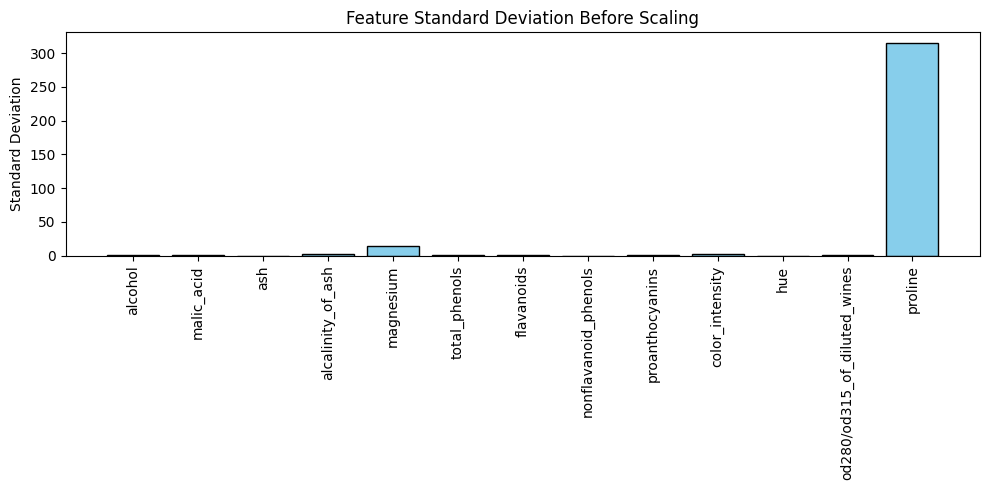

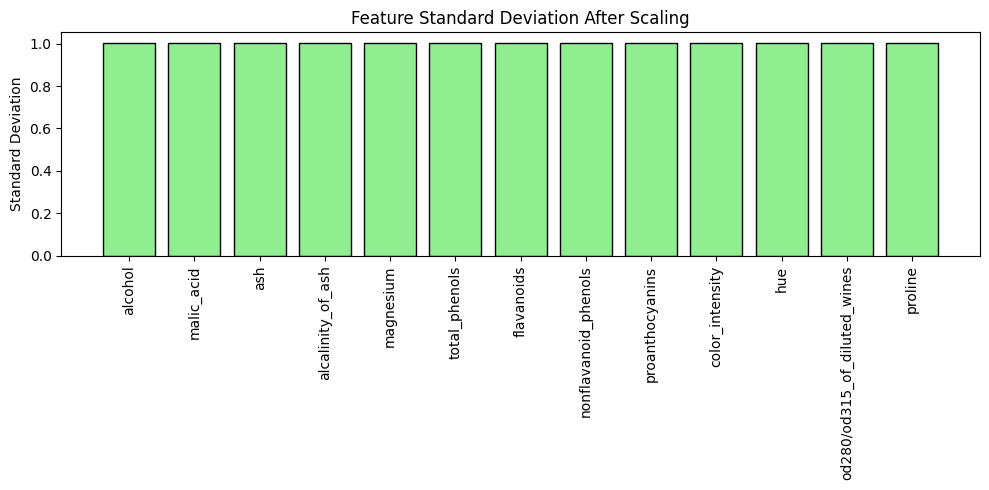

In [24]:
# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

# Plot
# Before scaling
plt.figure(figsize=(10, 5))
plt.bar(X.columns, X.std(), color='skyblue', edgecolor='black')
plt.title('Feature Standard Deviation Before Scaling')
plt.ylabel('Standard Deviation')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# After scaling
plt.figure(figsize=(10, 5))
plt.bar(X.columns, X_scaled_df.std(), color='lightgreen', edgecolor='black')
plt.title('Feature Standard Deviation After Scaling')
plt.ylabel('Standard Deviation')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()



Task 2:

 - Test K-Means Clustering (k = 1–10): Run K-Means with different numbers of clusters to determine how many groups best fit the dataset.

 - Elbow Method: Plot inertia (within-cluster sum of squares) for each k to identify where adding more clusters stops significantly improving the results.

 - Silhouette Scores (k = 2–10): Measure how well data points fit within their assigned clusters compared to other clusters. Higher scores indicate better-defined clusters.

 - Compare Both Methods: Display the Elbow and Silhouette plots side by side to evaluate the optimal number of clusters.

 - Identify Optimal k: Print the recommended k from each method to help select the best clustering configuration.

Optimal k (Elbow Method):     3
Optimal k (Silhouette Score): 3


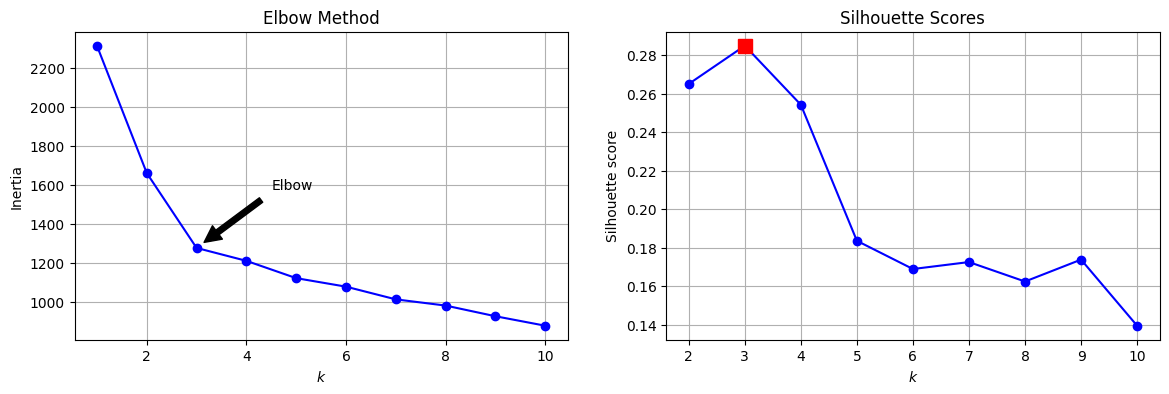

In [25]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Set Range
elbow_range = range(1, 11)
sil_range = range(2, 11)

# Fit k from 1 to 10 for K-Means
kmeans_per_k = [KMeans(n_clusters=k, random_state=42).fit(X_scaled)
                for k in elbow_range]

# Elbow Method: inertia for each k
inertias = [model.inertia_ for model in kmeans_per_k]

# Silhouette Scores for k in [2, 10]
silhouette_scores = [silhouette_score(X_scaled, model.labels_)
                     for model in kmeans_per_k[1:]]

# Optimal k for Elbow
optimal_k_elbow = np.argmax(np.diff(inertias, 2)) + 2

# Optimal k for Silhouette
optimal_k_sil = np.argmax(silhouette_scores) + 2

# Pring Optimal Ks 
print("Optimal k (Elbow Method):    ", optimal_k_elbow)
print("Optimal k (Silhouette Score):", optimal_k_sil)

# Plot 
# Elbow Method and Silhouette Scores
plt.figure(figsize=(14, 4))

plt.subplot(121)
plt.plot(range(1, 11), inertias, "bo-")
plt.xlabel("$k$")
plt.ylabel("Inertia")
plt.annotate("Elbow", xy=(optimal_k_elbow, inertias[optimal_k_elbow - 1]),
             xytext=(optimal_k_elbow + 1.5, inertias[optimal_k_elbow - 1] + 300),
             arrowprops=dict(facecolor='black', shrink=0.1))
plt.title("Elbow Method")
plt.grid()

plt.subplot(122)
plt.plot(sil_range, silhouette_scores, "bo-")
plt.plot(optimal_k_sil, silhouette_scores[optimal_k_sil - 2], "rs", markersize=10)
plt.xlabel("$k$")
plt.ylabel("Silhouette score")
plt.title("Silhouette Scores")
plt.grid()

plt.show()

Task 3: 

 - Apply PCA: Reduce the 13 standardized features to 2 principal components so the dataset can be visualized in a 2D graph.

 - Fit K-Means (k = 3): Train K-Means on the 2D PCA data to divide observations into 3 clusters based on their similarities.

 - Generate Voronoi Decision Boundaries: Use the Voronoi method to visualize how K-Means divides the 2D space based on the nearest cluster centroid.

 - Visualize Clusters: Plot the data points, cluster centers, and decision boundaries to understand how the clusters are separated.

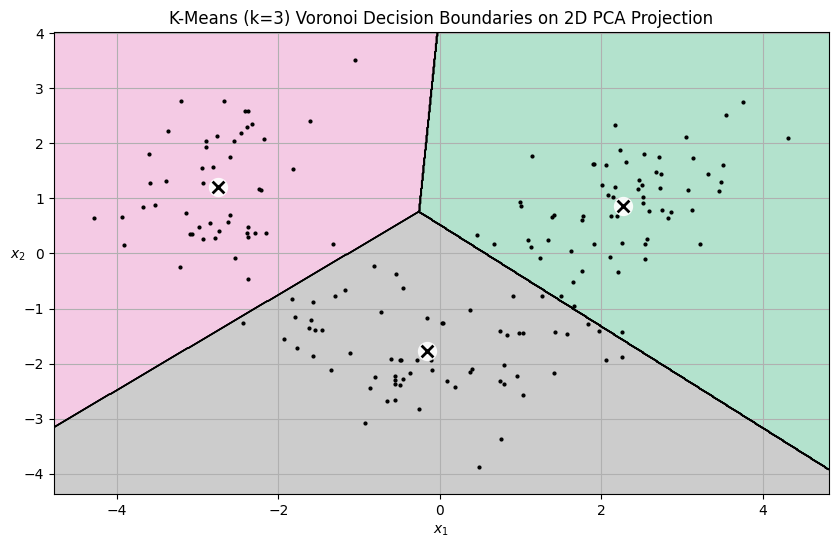

In [26]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# Reduce the 13 scaled features down to 2 principal
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# Fit K-Means (k=3) on the 2D projected space
kmeans_pca = KMeans(n_clusters=3, n_init=10, random_state=42)
kmeans_pca.fit(X_pca)

# Plotting helpers
def plot_data(X):
    plt.plot(X[:, 0], X[:, 1], 'k.', markersize=4)

def plot_centroids(centroids, circle_color='w', cross_color='k'):
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='o', s=35, linewidths=8,
                color=circle_color, zorder=10, alpha=0.9)
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='x', s=2, linewidths=12,
                color=cross_color, zorder=11, alpha=1)

def plot_decision_boundaries(clusterer, X, resolution=1000, show_centroids=True,
                             show_xlabels=True, show_ylabels=True):    
    mins = X.min(axis=0) - 0.5
    maxs = X.max(axis=0) + 0.5
    xx, yy = np.meshgrid(np.linspace(mins[0], maxs[0], resolution),
                         np.linspace(mins[1], maxs[1], resolution))
    Z = clusterer.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
                cmap="Pastel2")
    plt.contour(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
                linewidths=1, colors='k')
    plot_data(X)
    if show_centroids:
        plot_centroids(clusterer.cluster_centers_)

    if show_xlabels:
        plt.xlabel("$x_1$")
    else:
        plt.tick_params(labelbottom=False)
    if show_ylabels:
        plt.ylabel("$x_2$", rotation=0)
    else:
        plt.tick_params(labelleft=False)

# Plot the decision boundaries using the Voronoi method
plt.figure(figsize=(10, 6))
plot_decision_boundaries(kmeans_pca, X_pca)
plt.title("K-Means (k=3) Voronoi Decision Boundaries on 2D PCA Projection")
plt.grid()
plt.show()

Task 4:

 - Select 5 Wine Samples: Choose 5 representative samples from the dataset to examine how they relate to each cluster.

 - Use 13-Feature K-Means (k = 3): Use the K-Means model trained on all 13 standardized features to evaluate each sample without losing information through PCA.

 - Calculate Distance Matrix: Measure each sample's distance to all 3 cluster centroids to understand how closely it matches each cluster.

 - Generate Distance Heatmap: Visualize the distances using colors to make it easier to compare each sample's relationship to the clusters.

 - Highlight Hard Cluster Assignments: Identify the smallest distance for each sample, showing which cluster it belongs to.

Distance Matrix (13-feature K-Means, k=3):


,Cluster 0,Cluster 1,Cluster 2,Assigned Cluster,True Cultivar
Sample 0,4.963,6.293,2.063,2,0
Sample 40,3.975,5.548,1.829,2,0
Sample 80,2.255,5.821,4.785,0,1
Sample 120,2.396,4.936,3.715,0,1
Sample 160,4.372,1.839,5.755,1,2


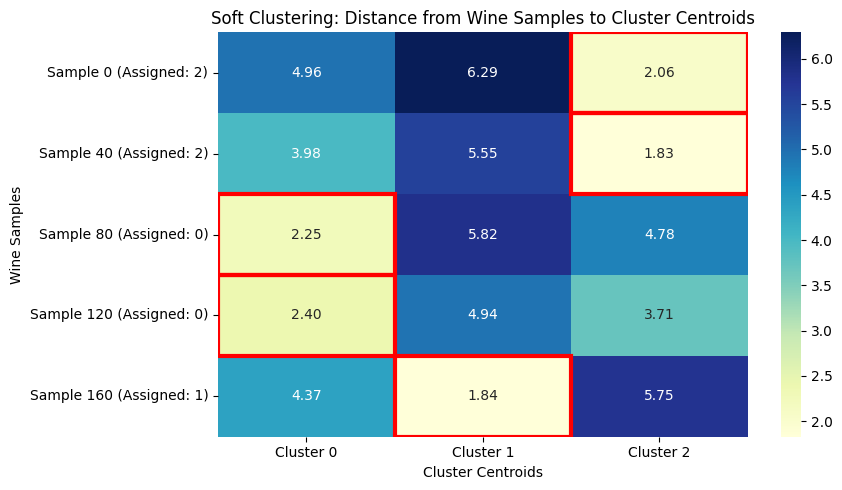

In [27]:
import seaborn as sns
from matplotlib.patches import Rectangle

# Fit 13-feature K-Means model (k=3)
kmeans_13 = KMeans(n_clusters=3, n_init=10, random_state=42)
kmeans_13.fit(X_scaled)

# Select 5 representative wine samples from the dataset
samples = [0, 40, 80, 120, 160]
X_samples = X_scaled[samples]

# Soft clustering distance profiles
distances = kmeans_13.transform(X_samples)

# Hard clustering assignment
hard_labels = kmeans_13.predict(X_samples)

# Display the distance matrix
dist_df = pd.DataFrame(distances.round(3),
                       columns=[f"Cluster {i}" for i in range(3)],
                       index=[f"Sample {i}" for i in samples])
dist_df["Assigned Cluster"] = hard_labels
dist_df["True Cultivar"] = y.iloc[samples].values
print("Distance Matrix (13-feature K-Means, k=3):")
display(dist_df)

# Generate and display a heatmap visualizing the 
# soft clustering distance profiles across all 
# 3 cluster centroids
plt.figure(figsize=(9, 5))
ax = sns.heatmap(
    distances,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    xticklabels=[f"Cluster {i}" for i in range(3)],
    yticklabels=[f"Sample {i} (Assigned: {c})" for i, c in zip(samples, hard_labels)]
)

# highlight the minimum distance corresponding to 
# each sample's hard cluster assignment
for row, col in enumerate(hard_labels):
    ax.add_patch(Rectangle((col, row), 1, 1, fill=False, edgecolor="red", lw=3))

plt.title("Soft Clustering: Distance from Wine Samples to Cluster Centroids")
plt.xlabel("Cluster Centroids")
plt.ylabel("Wine Samples")
plt.tight_layout()
plt.show()

Task 5: 

 - Apply DBSCAN Clustering: Train DBSCAN on all 13 standardized features to identify groups based on data density rather than a predefined number of clusters.

 - Experiment with Hyperparameters: Adjust eps (neighborhood distance) and min_samples (minimum points needed to form a dense region) to find suitable clustering settings.

 - Count Clusters and Noise Points: Print the number of clusters identified and the number of outliers (noise points) that do not belong to any cluster.

In [28]:
from sklearn.cluster import DBSCAN

# Experiment with the two DBSCAN hyperparameters
results = []
for min_samples in [3, 5, 8]:
    for eps in [1.5, 1.8, 2.0, 2.2, 2.3, 2.5, 2.7, 3.0]:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = list(labels).count(-1)
        results.append([min_samples, eps, n_clusters, n_noise])

results_df = pd.DataFrame(results, columns=["min_samples", "eps", "Clusters", "Noise Points"])
print("DBSCAN Hyperparameter Experiment:")
display(results_df)

# Fit a DBSCAN model on the 13-dimensional scaled feature space
dbscan = DBSCAN(eps=2.3, min_samples=3)
dbscan_labels = dbscan.fit_predict(X_scaled)

# Count clusters and noise points (-1 represents noise points)
n_clusters_ = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise_ = list(dbscan_labels).count(-1)

# Print the number of identified clusters and noise points.
print(f"Estimated number of clusters: {n_clusters_}")
print(f"Estimated number of noise points: {n_noise_}")

DBSCAN Hyperparameter Experiment:


,min_samples,eps,Clusters,Noise Points
0,3,1.5,8,147
1,3,1.8,8,90
2,3,2.0,5,64
3,3,2.2,3,44
4,3,2.3,3,32
5,3,2.5,1,23
6,3,2.7,1,18
7,3,3.0,2,7
8,5,1.5,0,178
9,5,1.8,7,118


Estimated number of clusters: 3
Estimated number of noise points: 32


Task 5: Plot
 - Visualize Using 2D PCA: Plot the DBSCAN results on the 2D PCA projection to better understand how the clusters are distributed.

 - Distinguish Noise and Core Points: Use different colors or markers to separate identified clusters, core points, and noise points.

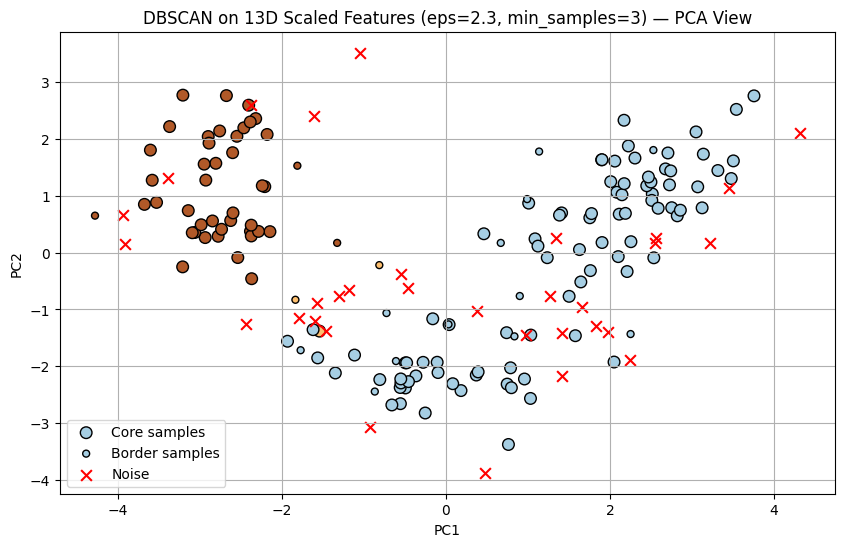

In [29]:
# Plot
# Visualize the DBSCAN assignments on the 2D PCA projection space, clearly
# distinguishing noise points from core cluster members
core_mask = np.zeros_like(dbscan_labels, dtype=bool)
core_mask[dbscan.core_sample_indices_] = True
noise_mask = dbscan_labels == -1
non_core_mask = ~(core_mask | noise_mask)

plt.figure(figsize=(10, 6))
plt.scatter(X_pca[core_mask, 0], X_pca[core_mask, 1],
            c=dbscan_labels[core_mask], cmap="Paired", marker="o", s=70,
            edgecolor="k", label="Core samples")
plt.scatter(X_pca[non_core_mask, 0], X_pca[non_core_mask, 1],
            c=dbscan_labels[non_core_mask], cmap="Paired", marker="o", s=25,
            edgecolor="k", label="Border samples")
plt.scatter(X_pca[noise_mask, 0], X_pca[noise_mask, 1],
            c="red", marker="x", s=60, label="Noise")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title(f"DBSCAN on 13D Scaled Features (eps=2.3, min_samples=3) — PCA View")
plt.legend()
plt.grid()
plt.show()

Task 6: 

 - Apply HDBSCAN Clustering: Train HDBSCAN on all 13 standardized features to identify clusters based on varying data densities.

 - Set Hyperparameters: Use min_cluster_size=5 or min_samples=5 to control the minimum cluster size or density requirements.

 - Count Clusters and Noise Points: Print the number of clusters discovered and the number of outliers that do not belong to any cluster.

 - Visualize Using 2D PCA: Plot the HDBSCAN cluster assignments on the 2D PCA projection to see how the clusters are distributed.

 - Distinguish Clusters and Noise: Use different colors for each cluster and a separate marker for noise points to clearly identify outliers.

Estimated number of HDBSCAN clusters: 2
Estimated number of HDBSCAN noise points: 58


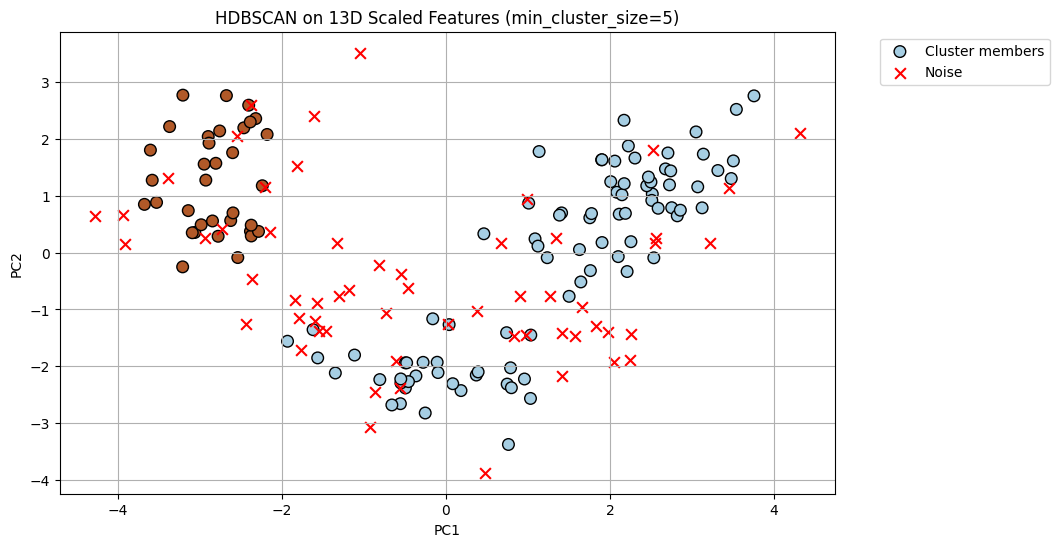

In [30]:
from sklearn.cluster import HDBSCAN

# Fit HDBSCAN model (using min_cluster_size=5)
# on the 13-dimensional scaled feature space
hdbscan_model = HDBSCAN(min_cluster_size=5)
hdbscan_labels = hdbscan_model.fit_predict(X_scaled)

# Count clusters and noise points (-1 represents noise points)
n_hdbscan_clusters_ = len(set(hdbscan_labels)) - (1 if -1 in hdbscan_labels else 0)
n_hdbscan_noise_ = list(hdbscan_labels).count(-1)

# Print the total number of clusters discovered and noise points detected
print(f"Estimated number of HDBSCAN clusters: {n_hdbscan_clusters_}")
print(f"Estimated number of HDBSCAN noise points: {n_hdbscan_noise_}")

# Visualize the resulting HDBSCAN assignments on the 2D PCA projection
noise_mask = hdbscan_labels == -1

plt.figure(figsize=(10, 6))
plt.scatter(X_pca[~noise_mask, 0], X_pca[~noise_mask, 1],
            c=hdbscan_labels[~noise_mask], cmap="Paired", marker="o", s=70,
            edgecolor="k", label="Cluster members")
plt.scatter(X_pca[noise_mask, 0], X_pca[noise_mask, 1],
            c="red", marker="x", s=60, label="Noise")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("HDBSCAN on 13D Scaled Features (min_cluster_size=5)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid()
plt.show()

Task 7: 

 - Apply Hierarchical Clustering: Use single-linkage clustering on all 13 standardized wine features to group samples based on their similarities.
 
 - Compute Linkage Matrix: Calculate the distances at which individual wine samples and clusters merge together.
 
 - Generate Dendrogram: Plot a tree diagram showing how wine samples progressively merge into larger clusters.
 
 - Analyze Distance Thresholds: Examine where clusters merge to understand their similarities and identify potential cluster structures.
 
 - Connect to HDBSCAN: Compare the hierarchical structure to how HDBSCAN uses density-based relationships and cluster stability to identify meaningful groups


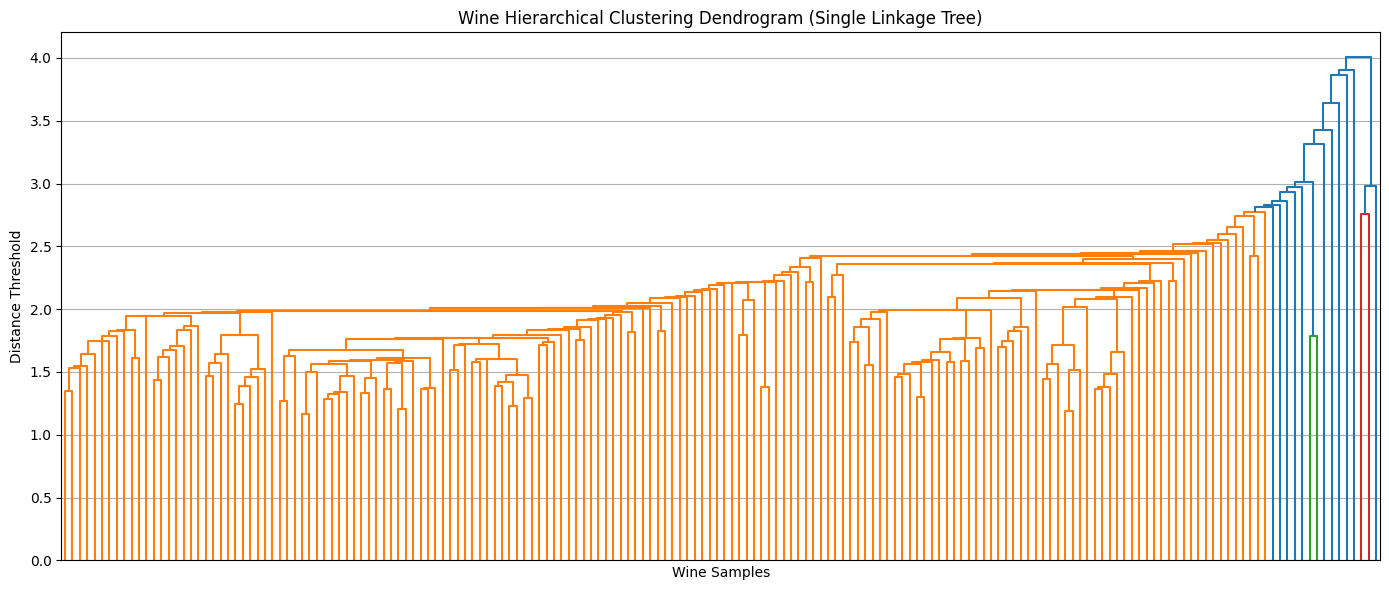

In [31]:
from scipy.cluster.hierarchy import dendrogram, linkage

# Compute the single-linkage hierarchical clustering matrix on the Wine features
linked = linkage(X_scaled, method='single')

# Plot hierarchical clustering dendrogram
plt.figure(figsize=(14, 6))
dendrogram(
    linked,
    orientation='top',
    distance_sort='descending',
    show_leaf_counts=False,
    no_labels=True
)

plt.title('Wine Hierarchical Clustering Dendrogram (Single Linkage Tree)')
plt.xlabel('Wine Samples')
plt.ylabel('Distance Threshold')
plt.grid(True)
plt.tight_layout()
plt.show()

Task 8:

 - Use Cluster Labels as Features: Treat the cluster assignments from K-Means, DBSCAN, and HDBSCAN as categorical inputs to predict the actual wine cultivars.
 
 - Split the Dataset (80/20): Use a stratified split to reserve 80% of the data for training and 20% for testing while maintaining the proportion of each wine class.

 - Train Supervised Classifiers: Use Random Forest or Logistic Regression to predict the actual wine classes (0, 1, 2) using each algorithm's cluster labels.

 - Calculate Classification Accuracy: Measure how accurately each model predicts the true wine cultivars on the test set.

 - Calculate Silhouette Scores: Evaluate how well-separated the clusters are for each algorithm using the standardized features.


In [32]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, silhouette_score

# Cluster assignments from each algorithm used as pseudo-label features
cluster_labels = {
    "K-Means (k=3)": kmeans_13.labels_,
    "DBSCAN": dbscan_labels,
    "HDBSCAN": hdbscan_labels,
}

names = []
accuracies = []
silhouettes = []

for name, labels in cluster_labels.items():
    # One-hot encode the cluster labels as categorical features (noise -1 becomes its own category)
    X_clusters = pd.get_dummies(pd.Series(labels, name="cluster").astype(str)).values

    # 80/20 split
    X_train, X_test, y_train, y_test = train_test_split(
        X_clusters, y, test_size=0.20, stratify=y, random_state=42
    )

    rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)
    rf_clf.fit(X_train, y_train)
    acc = accuracy_score(y_test, rf_clf.predict(X_test))

    # Silhouette score on scaled features (noise points excluded)
    mask = labels != -1
    sil = silhouette_score(X_scaled[mask], labels[mask])

    names.append(name)
    accuracies.append(acc)
    silhouettes.append(sil)
    print(f"{name:<15} Accuracy: {acc:.4f}   Silhouette: {sil:.4f}   Noise points: {(~mask).sum()}")

K-Means (k=3)   Accuracy: 0.9722   Silhouette: 0.2849   Noise points: 0
DBSCAN          Accuracy: 0.7222   Silhouette: 0.2249   Noise points: 32
HDBSCAN         Accuracy: 0.7500   Silhouette: 0.3524   Noise points: 58


Task 8: Plot

 - Compare Results: Plot classification accuracy and Silhouette Scores for all three clustering algorithms to compare their performance.

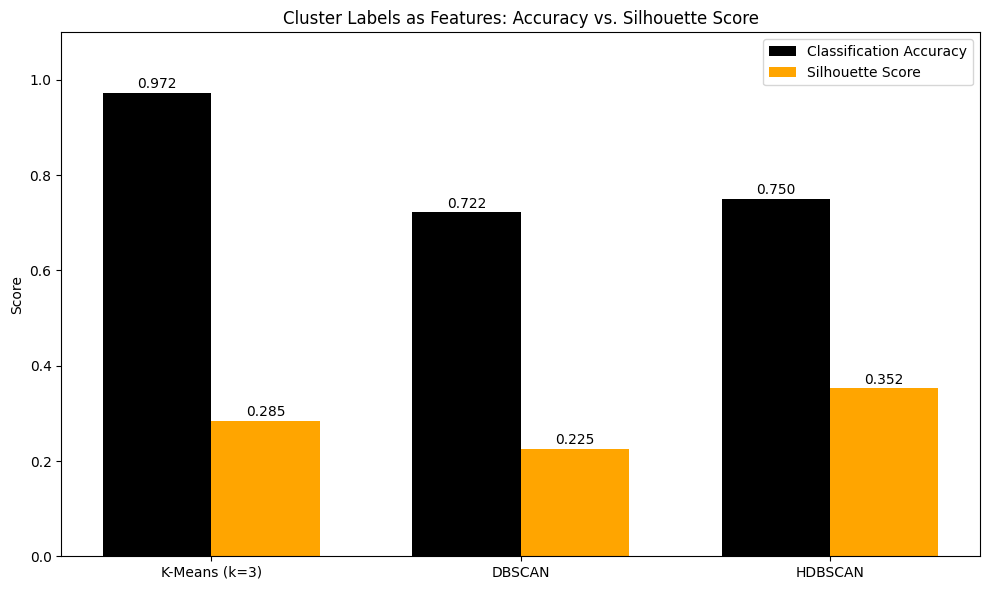

In [33]:
# Plot 
# Classification Accuracy and Silhouette Score per algorithm
x = np.arange(len(names))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width/2, accuracies, width, color="black", label="Classification Accuracy")
bars2 = ax.bar(x + width/2, silhouettes, width, color="orange", label="Silhouette Score")

ax.set_ylabel("Score")
ax.set_ylim(0, 1.1)
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_title("Cluster Labels as Features: Accuracy vs. Silhouette Score")

for b in list(bars1) + list(bars2):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01, f"{b.get_height():.3f}", ha="center")

ax.legend(loc="upper right")

plt.tight_layout()
plt.show()